# Project 2: Credit Card Fraud Detection

**Course:** DSC8307 Data Mining, Modeling and Analytics  
**Programme:** MSc Data Science and Analytics  

## Task
Build an anomaly detector that prioritizes transactions for fraud investigation, then evaluate  its ranking against the withheld fraud labels.
1. Explore and write a short report on the data and carryout necessary data preparation, with
justification. Establish a statistical outlier baseline.
2. Compare the performance of a cluster-based and a classification-based approach to identifying the
anomalous transactions. Justify your choice of each kind of approach.
3. Explain why an unusual transaction is not necessarily fraudulent.

### Setup & Imports

In [1]:
# ============================================================

# Setup, imports and global configuration
# ============================================================

# --- Standard library ---
import os
import warnings
from pathlib import Path

# --- Core data handling ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & decomposition ---
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split

# --- Evaluation metrics ---
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

# --- Statistical outlier baseline ---
from sklearn.covariance import EmpiricalCovariance, MinCovDet
from sklearn.ensemble import IsolationForest

# --- Cluster-based anomaly detection ---
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# --- Classification-based detection ---
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# --- Reproducibility & display ---
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Plotting defaults ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# --- Path ---
DATA_PATH = Path("creditcard.csv")
assert DATA_PATH.exists(), (
    f"Dataset not found at '{DATA_PATH.resolve()}'. "
    "Place 'creditcard.csv' in the same folder as this notebook."
)

print("Environment ready.")
print(f"  numpy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  seaborn     : {sns.__version__}")
print(f"  RANDOM_STATE: {RANDOM_STATE}")

Environment ready.
  numpy       : 2.3.5
  pandas      : 2.3.3
  seaborn     : 0.13.2
  RANDOM_STATE: 42


### Load Data & First Look

In [2]:
# ============================================================
# Loading the credit card dataset
# ============================================================

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


### Data Quality Checks

In [3]:
# ============================================================
# Data Quality Checks
# ============================================================

# 1. Checking for missing values
print("Missing values per column (sum):")
missing_counts = df.isna().sum()
print(f"Total missing: {missing_counts.sum()}")
# Showing only columns with missing values, if any
if missing_counts.sum() > 0:
    display(missing_counts[missing_counts > 0])
else:
    print("-> No missing values found in any column.")

# 2. Checking for duplicate rows
n_duplicates = df.duplicated().sum()
print(f"\nDuplicate rows: {n_duplicates}")

# 3. Checking for negative values in Time and Amount (these should be strictly non-negative)
n_neg_time = (df["Time"] < 0).sum()
n_neg_amount = (df["Amount"] < 0).sum()
print(f"\nNegative values in 'Time':   {n_neg_time}")
print(f"Negative values in 'Amount': {n_neg_amount}")

# 4. Checking the target variable (Class)
print(f"\nTarget variable 'Class' values:")
print(df["Class"].value_counts())
print(f"\nFraud rate: {(df['Class'].mean() * 100):.4f}%")

Missing values per column (sum):
Total missing: 0
-> No missing values found in any column.

Duplicate rows: 1081

Negative values in 'Time':   0
Negative values in 'Amount': 0

Target variable 'Class' values:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%


### Data Quality Assessment

The data quality checks produced the following findings:

- **Missing values:** None. All 31 columns are fully populated across the 284,807 rows.
- **Negative values:** None in `Time` or `Amount`. 
- **Duplicate rows:** **1,081 duplicate records** were detected.
- **Target variable:** The `Class` column contains 284,315 non-fraud cases (99.827%) and 492 fraud cases (0.173%). This confirms the extreme class imbalance described in the dataset documentation.

**On the duplicates:** Because of the extreme rarity of fraud, even a small number of duplicated fraudulent records could significantly inflate the observed fraud rate and leak into the test set during evaluation.

**Decision:** The duplicate rows will be **removed** before any modelling. This prevents data leakage (where a transaction appears in both train and test sets) and ensures the reported performance reflects the model's ability to generalise to new, unseen transactions. 

### Inspecting Duplicate Rows

In [4]:
# ============================================================
# Inspecting Duplicate Rows
# ============================================================
# Checking how many extra copies exist and whether any of them are fraud.

# Isolationg only the extra duplicate copies that will be removed
duplicate_mask = df.duplicated(keep='first')
duplicate_rows = df[duplicate_mask].sort_values(by="Class", ascending=False)

print(f"Total extra copies to be removed: {len(duplicate_rows)}")
print(f"Of which are fraud (Class=1): {duplicate_rows['Class'].sum()}\n")

print("Top 6 extra copies (showing a subset of columns for readability):")
display(duplicate_rows[["Time", "V1", "V2", "Amount", "Class"]].head(6))

Total extra copies to be removed: 1081
Of which are fraud (Class=1): 19

Top 6 extra copies (showing a subset of columns for readability):


,Time,V1,V2,Amount,Class
150678,"93,879.0000",-13.0865,7.3521,30.3100,1
102446,"68,207.0000",-13.1927,12.7860,1.0000,1
151008,"94,362.0000",-26.4577,16.4975,1.0000,1
151009,"94,362.0000",-26.4577,16.4975,1.0000,1
150680,"93,879.0000",-12.8336,7.5088,104.0300,1
150669,"93,860.0000",-10.6324,7.2519,188.5200,1


### Duplicate Inspection

Before dropping the duplicate records, the extra copies were inspected to check whether any of them were fraud cases and to see what the duplicates actually look like. 

The findings were:
- **Extra copies to be removed:** 1,081
- **Of which are fraud (`Class = 1`):** 19

The sample displayed above shows a subset of these extra copies (only a few columns are visible for readability). It is important to note that these six rows are not duplicates *of each other*; rather, they are six separate fraud transactions, each of which has an identical twin somewhere else in the dataset.

**Decision:** The 1,081 extra copies are still removed. The reason is that an exact 31-column match contributes no new information to the model. If a copy is retained and lands in both the training and test sets, the model is rewarded for memorising it, which inflates the reported fraud detection performance. Removing them is the standard practice for this dataset and ensures the evaluation reflects the model's ability to generalise to new, unseen transactions.

### Dropping Duplicates & Recounting

In [5]:
# ============================================================
# Dropping Duplicates and Recounting
# ============================================================

# Dropping the exact duplicate rows, keeping the first occurrence
df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f"Original shape: {df.shape}")
print(f"Cleaned shape:  {df_clean.shape}")
print(f"Rows dropped:   {df.shape[0] - df_clean.shape[0]}")

# Checking the new class balance
print("\nClass balance after cleaning:")
print(df_clean["Class"].value_counts())

fraud_after = df_clean["Class"].sum()
total_after = len(df_clean)
print(f"\nNew fraud rate: {(fraud_after / total_after * 100):.4f}%")

# Overwriting df with the cleaned version for the rest of the analysis
df = df_clean

Original shape: (284807, 31)
Cleaned shape:  (283726, 31)
Rows dropped:   1081

Class balance after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64

New fraud rate: 0.1667%


### Final Data Quality Outcome

After removing the 1,081 extra copies, the cleaned dataset contains **283,726 rows** and the same 31 columns. 

The class balance shifted slightly:
- **Non-fraud (`Class = 0`):** 283,253
- **Fraud (`Class = 1`):** 473
- **Fraud rate:** 0.1667% (down from 0.1727%)

The 19 fraudulent extra copies that were removed account for the difference between the original 492 frauds and the 473 remaining. The extreme imbalance persists: the model still faces a 1-in-600 chance of seeing a fraud in any given transaction. 

### Summary of the Data Quality Assessment

| Check | Result | Decision |
|---|---|---|
| Missing values | None | No action needed |
| Negative values in `Time` / `Amount` | None | No action needed |
| Exact duplicate rows | 1,081 extra copies (19 fraud) | Removed to prevent data leakage |
| Class imbalance | 0.1667% fraud after cleaning | Addressed via class weights and metric choice in the modelling section |


### Exploratory Data Analysis

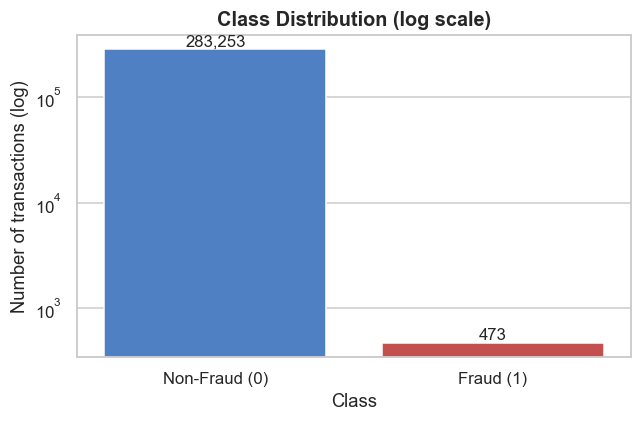

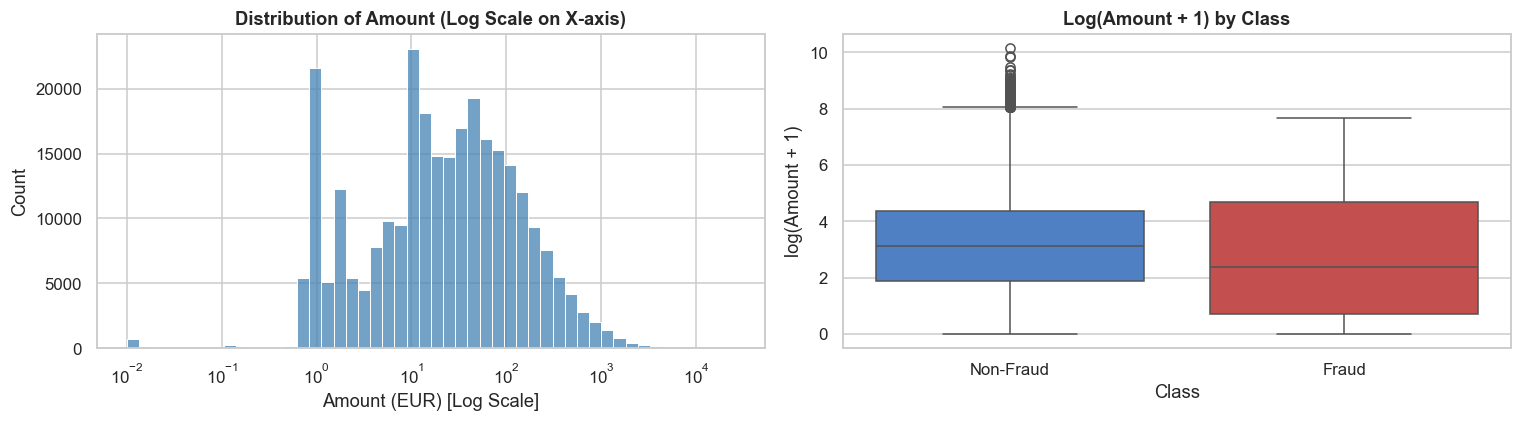

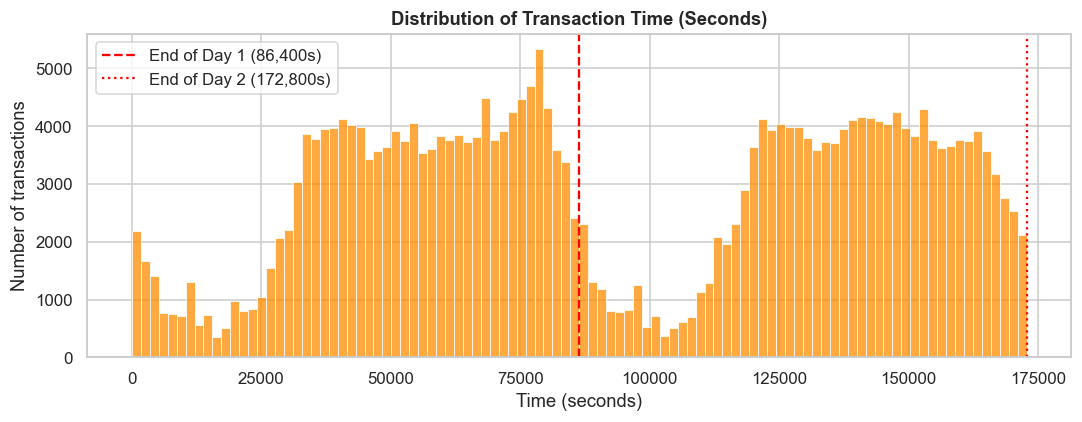

In [6]:
# ============================================================
# Exploratory Data Analysis
# ============================================================
# Visualising the fundamental characteristics of the dataset: 
# the imbalance, the distribution of Time and Amount, and the separation of the PCA components between classes.

# 1. Class imbalance visualisation
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Class", data=df, ax=ax, palette=["#3b7dd8", "#d83b3b"])
ax.set_xticklabels(["Non-Fraud (0)", "Fraud (1)"])
ax.set_yscale("log")  # Log scale to make the 473 frauds visible alongside 283,253
ax.set_title("Class Distribution (log scale)", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of transactions (log)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.tight_layout()
plt.show()

# 2. Amount Histogram (using log scale on the x-axis)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram with log-scaled x-axis
sns.histplot(df["Amount"], bins=50, ax=axes[0], color="steelblue", log_scale=True)
axes[0].set_title("Distribution of Amount (Log Scale on X-axis)")
axes[0].set_xlabel("Amount (EUR) [Log Scale]")

# Boxplot of Log-Transformed Amount (using np.log1p)
# Adding a small temporary column for the plot
sns.boxplot(x="Class", y=np.log1p(df["Amount"]), data=df, ax=axes[1], palette=["#3b7dd8", "#d83b3b"])
axes[1].set_xticklabels(["Non-Fraud", "Fraud"])
axes[1].set_title("Log(Amount + 1) by Class")
axes[1].set_ylabel("log(Amount + 1)")
plt.tight_layout()
plt.show()

# 3. Time Histogram
plt.figure(figsize=(10, 4))
sns.histplot(df["Time"], bins=100, color="darkorange")
plt.axvline(x=86400, color='red', linestyle='--', label="End of Day 1 (86,400s)")
plt.axvline(x=172800, color='red', linestyle=':', label="End of Day 2 (172,800s)")
plt.title("Distribution of Transaction Time (Seconds)")
plt.xlabel("Time (seconds)")
plt.ylabel("Number of transactions")
plt.legend()
plt.tight_layout()
plt.show()

### Exploratory Data Analysis

The exploratory plots reveal three critical characteristics about the dataset:

**1. Extreme Class Imbalance**
The bar chart (using a logarithmic y-axis to make the minority class visible) shows 283,253 non-fraud transactions against only 473 fraud cases. This imbalance mandates the use of ranking metrics (PR-AUC, precision, recall) rather than simple accuracy.

**2. The Shape of Transaction Amounts**
By applying a logarithmic scale to the x-axis, the histogram reveals that `Amount` is heavily right-skewed with distinct spikes at round numbers (e.g., €1, €10, €100), typical of retail pricing. 
The boxplot of `log(Amount + 1)` shows two key differences between the classes. Firstly, the median transaction amount for fraud (red) is lower than for non-fraud (blue), meaning typical fraudulent charges are small. Secondly, the non-fraud class has a long upper tail of extreme values stretching past `log(Amount) = 10` (over €20,000), whereas the fraud class maxes out much lower and shows no visible outliers beyond its upper whisker. Because the raw `Amount` column spans several orders of magnitude, it must be log-transformed and scaled before use in any distance-based algorithm.

**3. The Two-Day Cycle**
The `Time` plot shows a clear daily rhythm. The red dashed line at 86,400 seconds marks the end of Day 1. The first peak represents active daytime hours, followed by a valley (night-time), and the second peak represents the daytime hours of Day 2. The cyclical nature of the data confirms that the transactions are non-stationary over time, therefore, `Time` should be treated carefully during train-test splitting to avoid temporal leakage.

### Data Preparation (Transformation & Scaling)

In [7]:
# ============================================================
# Data Preparation with Cyclical Time
# ============================================================
# 1. Converting Time (seconds) into a cyclical feature (Sine and Cosine)
# This allows distance-based models to understand that 23:59 is close to 00:01.

# Extracting seconds since midnight
df['Seconds_in_day'] = df['Time'] % 86400

# Applying Sine and Cosine transformations
df['Time_Sin'] = np.sin(2 * np.pi * df['Seconds_in_day'] / 86400)
df['Time_Cos'] = np.cos(2 * np.pi * df['Seconds_in_day'] / 86400)

# 2. Log-transforming Amount to compress the right-skew
df['Log_Amount'] = np.log1p(df['Amount'])

# 3. Standardising Amount to match the scale of the PCA components
# (Time_Sin and Time_Cos are already bounded between -1 and 1)
std_scaler = StandardScaler()
df['Scaled_Amount'] = std_scaler.fit_transform(df[['Log_Amount']])

# 4. Dropping the original Time, Amount, and the temporary columns
df = df.drop(['Time', 'Amount', 'Log_Amount', 'Seconds_in_day'], axis=1)

print("Prepared dataset columns:")
print(df.columns.tolist()[:5], "... (V features) ...", df.columns.tolist()[-4:])

df.head()

Prepared dataset columns:
['V1', 'V2', 'V3', 'V4', 'V5'] ... (V features) ... ['Class', 'Time_Sin', 'Time_Cos', 'Scaled_Amount']


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class,Time_Sin,Time_Cos,Scaled_Amount
0,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,0,0.0000,1.0000,1.1231
1,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,0,0.0000,1.0000,-1.1153
2,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,0,0.0001,1.0000,1.6810
3,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,0,0.0001,1.0000,1.0081
4,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,0,0.0001,1.0000,0.6691


### Data Preparation

The exploratory analysis justified three preparation steps:

1. **Cyclical encoding of `Time`:** The raw `Time` column is a continuous counter of seconds. Distance-based algorithms and tree-based models treat `Time = 10,800` (3 AM on Day 1) and `Time = 97,200` (3 AM on Day 2) as completely different values, even though both represent the same hour of the day. To preserve the time-of-day signal without confusing the model across days, the seconds-since-midnight were extracted and converted into two cyclical features, `Time_Sin` and `Time_Cos`. This ensures that 23:59 and 00:01 are mathematically close, and that the model can learn that certain hours are more fraud-prone regardless of which day it is.

2. **Log-transformation of `Amount`:** The raw `Amount` distribution is heavily right-skewed (ranging from cents to tens of thousands of euros). A `log1p` transformation was applied to compress the long upper tail and reduce the distortion that extreme values would otherwise introduce in distance-based methods.

3. **Standardisation of `Amount`:** `StandardScaler` was applied so that `Scaled_Amount` has mean 0 and standard deviation 1, matching the scale of the PCA components `V1`–`V28`. This keeps `Amount` contributing comparably in the distance calculations rather than being down-weighted by its different scale. The `Time_Sin` and `Time_Cos` features were left as-is because they are already bounded between −1 and 1.

The raw `Time`, `Amount`, the temporary `Log_Amount`, and the intermediate `Seconds_in_day` columns were dropped. The prepared dataset contains `V1`–`V28`, `Class`, `Time_Sin`, `Time_Cos`, and `Scaled_Amount`.

The `V1`–`V28` columns were left unchanged: they were already produced by a PCA transformation on standardised inputs, so they are centred near zero with comparable variance.

### Statistical Outlier Baseline (Mahalanobis Distance)

In [8]:
# ============================================================
# Temporal Split & Mahalanobis Baseline
# ============================================================
# Sorting by the dataframe index, since is still in time order from the start.
# Using .iloc slices the data by row position: 
#   - First 70% of rows = earlier transactions (training)
#   - Last 30% of rows  = later transactions (test)

split_idx = int(len(df) * 0.7)

train_df = df.iloc[:split_idx].copy()
test_df  = df.iloc[split_idx:].copy()

X_train = train_df.drop("Class", axis=1)
y_train = train_df["Class"]
X_test  = test_df.drop("Class", axis=1)
y_test  = test_df["Class"]

print(f"Train set: {len(X_train)} rows (Frauds: {y_train.sum()})")
print(f"Test set:  {len(X_test)} rows (Frauds: {y_test.sum()})")
print(f"Test set fraud rate: {y_test.mean() * 100:.4f}%")

# Fitting Mahalanobis on the non-fraud training data
X_train_legit = X_train[y_train == 0]
mean_legit = np.asarray(X_train_legit.mean(axis=0))
cov_legit = np.cov(np.asarray(X_train_legit), rowvar=False)
inv_cov_legit = np.linalg.pinv(cov_legit)

# Scoring the test set
diff = np.asarray(X_test) - mean_legit
maha_dist = np.sqrt(np.einsum('ij, jk, ik -> i', diff, inv_cov_legit, diff))

# Evaluating: precision@k, recall@k, PR-AUC
def evaluate_model(scores, y_true, k_values=[10, 100, 500, 1000]):
    df_rank = pd.DataFrame({"score": scores, "y_true": y_true.values})
    df_rank = df_rank.sort_values("score", ascending=False).reset_index(drop=True)
    total_frauds = y_true.sum()
    results = {"PR_AUC": average_precision_score(y_true, scores)}
    for k in k_values:
        tp = df_rank.head(k)["y_true"].sum()
        results[f"P@{k}"] = tp / k * 100
        results[f"R@{k}"] = tp / total_frauds * 100
    return results

maha_results = evaluate_model(maha_dist, y_test)

print("\nMahalanobis Baseline Performance (Chronological Split & Cyclical Time):")
print(f"  PR-AUC: {maha_results['PR_AUC']:.4f}")
for k in [10, 100, 500, 1000]:
    print(f"  Precision@{k:<4}: {maha_results[f'P@{k}']:6.2f}%   Recall@{k:<4}: {maha_results[f'R@{k}']:6.2f}%")

Train set: 198608 rows (Frauds: 366)
Test set:  85118 rows (Frauds: 107)
Test set fraud rate: 0.1257%

Mahalanobis Baseline Performance (Chronological Split & Cyclical Time):
  PR-AUC: 0.1506
  Precision@10  :   0.00%   Recall@10  :   0.00%
  Precision@100 :  17.00%   Recall@100 :  15.89%
  Precision@500 :  15.40%   Recall@500 :  71.96%
  Precision@1000:   8.50%   Recall@1000:  79.44%


### Statistical Outlier Baseline (Chronological Split)

The Mahalanobis distance was used to establish a statistical baseline. The model was fitted on the non-fraud transactions from the training set (the first 70% of the timeline) and scored the test set (the final 30% of the timeline).

**Ranking Performance:**
- **Fraud rate in the test set:** 0.1257%
- **PR-AUC:** 0.1506
- **Precision@10:** 0.00%  |  **Recall@10:** 0.00%
- **Precision@100:** 17.00%  |  **Recall@100:** 15.89%
- **Precision@500:** 15.40%  |  **Recall@500:** 71.96%
- **Precision@1000:** 8.50%  |  **Recall@1000:** 79.44%

**Interpretation & Concept Drift:**

The Mahalanobis baseline demonstrates some ability to distinguish fraudulent transactions from legitimate ones, but its performance varies considerably across ranking cut-offs. Its Precision@100 of 17.00% is substantially higher than the overall test fraud rate of 0.1257%, indicating that it successfully concentrates fraudulent transactions near the top of the ranking. A PR-AUC of 0.1506, though modest in absolute terms, is roughly 120 times the fraud prevalence and therefore far above what a random ranking would achieve. At the very top of the ranking (top 10), the baseline fails to identify any fraudulent transactions.

Recall reveals a different side of the same picture. By the top 500, the baseline has surfaced **71.96%** of all test frauds, and by the top 1,000 it has surfaced **79.44%**. In practical terms, an investigator willing to review 1,000 transactions would see roughly 4 out of every 5 frauds, but at the cost of a large number of false positives, since precision at that budget is only 8.50%. The trade-off between recall and precision is therefore steep, and the choice of operating budget matters more than the raw score.

One possible explanation for the baseline's limitations is **concept drift**. The Mahalanobis baseline assumes that legitimate spending behaviour follows a relatively stable multivariate Gaussian distribution and that fraudulent transactions tend to deviate from this distribution. However, spending behaviour and fraud patterns can change over time. If legitimate transaction patterns shift between the training and testing periods, or fraudsters adopt spending behaviours that resemble legitimate transactions observed during training, the distance-based approach may fail to identify them effectively. The chronological evaluation therefore exposes the limitations of relying on a static statistical representation of legitimate behaviour. It should be noted, however, that these results alone do not establish concept drift as the cause — the Gaussian assumption itself, and the very small number of frauds at the very top of the ranking, are equally plausible explanations.

Two conclusions follow:

1. **The baseline establishes a meaningful performance benchmark.** Despite its limitations, the 17.00% Precision@100 and 0.1506 PR-AUC demonstrate that statistical distance can identify potentially suspicious transactions. Subsequent machine learning models should therefore demonstrate measurable improvements over this benchmark at equivalent ranking cut-offs and on the same test set.
2. **The baseline is a useful reference, not necessarily a competitive final solution.** Its reliance on statistical distance, without learning from fraud labels or adapting to changing transaction patterns, limits its ability to capture more complex fraud behaviour. The GMM and classification models that follow will be evaluated against this baseline to determine whether their additional complexity translates into better fraud detection performance.

### Cluster-Based Anomaly Detection (Gaussian Mixture Model)

In [9]:
# ============================================================
# Cluster-Based Anomaly Detection (GMM)
# ============================================================
from sklearn.mixture import GaussianMixture

# 1. Fitting the GMM on the legitimate training data only
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=RANDOM_STATE)
gmm.fit(X_train_legit)

# 2. Scoring the test set
# score_samples returns the log-likelihood (higher = more normal)
# Negating it makes higher = more anomalous (like a distance)
test_ll = gmm.score_samples(X_test)
gmm_anomaly_scores = -test_ll

# 3. Evaluating the rankings
gmm_results = evaluate_model(gmm_anomaly_scores, y_test)

print("GMM Cluster-Based Anomaly Detection (k=5):")
print(f"  PR-AUC: {gmm_results['PR_AUC']:.4f}")
for k in [10, 100, 500, 1000]:
    print(f"  Precision@{k:<4}: {gmm_results[f'P@{k}']:6.2f}%   Recall@{k:<4}: {gmm_results[f'R@{k}']:6.2f}%")

GMM Cluster-Based Anomaly Detection (k=5):
  PR-AUC: 0.1838
  Precision@10  :   0.00%   Recall@10  :   0.00%
  Precision@100 :  27.00%   Recall@100 :  25.23%
  Precision@500 :  14.80%   Recall@500 :  69.16%
  Precision@1000:   8.50%   Recall@1000:  79.44%


### Cluster-Based Anomaly Detection (Gaussian Mixture Model)

The Gaussian Mixture Model (GMM) was fitted on the non-fraud training data only, using five Gaussian components (k=5) with full covariance. Each test transaction was scored using its negative log-likelihood under the fitted mixture, such that transactions with low likelihood under the learned distribution of legitimate behaviour received higher anomaly scores. The resulting rankings were evaluated using the same Precision@K, Recall@K, and PR-AUC metrics applied to the Mahalanobis baseline.

**Ranking Performance:**
- **PR-AUC:** 0.1838
- **Precision@10:** 0.00%  |  **Recall@10:** 0.00%
- **Precision@100:** 27.00%  |  **Recall@100:** 25.23%
- **Precision@500:** 14.80%  |  **Recall@500:** 69.16%
- **Precision@1000:** 8.50%  |  **Recall@1000:** 79.44%

**Comparison with the Statistical Baseline:**

| Metric | Mahalanobis Baseline | GMM (k=5) |
|---|---:|---:|
| PR-AUC | 0.1506 | **0.1838** |
| Precision@10 | 0.00% | 0.00% |
| Recall@10 | 0.00% | 0.00% |
| Precision@100 | 17.00% | **27.00%** |
| Recall@100 | 15.89% | **25.23%** |
| Precision@500 | **15.40%** | 14.80% |
| Recall@500 | **71.96%** | 69.16% |
| Precision@1000 | 8.50% | 8.50% |
| Recall@1000 | **79.44%** | **79.44%** |

**Interpretation**

The GMM improves on the Mahalanobis baseline at the most decision-relevant part of the ranking. **PR-AUC rises from 0.1506 to 0.1838**, and **Precision@100 increases from 17.00% to 27.00%** . **Recall@100 rises in parallel, from 15.89% to 25.23%**, meaning a quarter of all test frauds are surfaced within the first 100 alerts.

The improvement is concentrated at the top of the ranking and is less consistent at higher budgets. Both methods achieve 0.00% Precision@10, the GMM is marginally worse at Precision@500 (14.80% vs 15.40%), and the two methods tie at Precision@1000. Recall@500 is also slightly lower for the GMM (69.16% vs 71.96%), confirming that the Mahalanobis baseline has a marginal edge in the *middle* of the ranking even where the GMM leads at the top.

**Why the GMM improves at the top**

The improvement at Precision@100 and Recall@100 suggests that modelling legitimate behaviour as a *mixture* of Gaussian components is better than a single multivariate Gaussian. The five components each capture a different mode of legitimate behaviour, with their own mean and covariance, so a transaction is evaluated against several learned patterns rather than one global distribution. This flexibility pays off in the region of the ranking where transactions are unusual but not extreme: they can be scored as "unlikely under every mode" rather than "far from a single centre". At the very top of the ranking extreme outliers, the mixture flexibility does not help (hence 0% Precision@10 for both methods), because those points are far from *all* modes.

**Limitations of the Cluster-Based Approach**

Despite its improvement at Precision@100 and PR-AUC, the GMM remains an unsupervised anomaly detection method. Because it is trained exclusively on legitimate transactions, it does not learn directly from the characteristics that distinguish fraudulent transactions from unusual-but-legitimate ones. A transaction with low likelihood under the learned distribution is therefore not necessarily fraudulent, it may simply be rare. Its performance depends on how accurately the Gaussian mixture captures the true shape of legitimate behaviour.

The GMM also does not guarantee consistent improvements across ranking budgets, as shown by its lower Precision@500 and Recall@500 relative to the baseline. The classification-based approach that follows addresses the main limitation of unsupervised anomaly detection by learning from labelled fraud and non-fraud transactions.

### Classification-Based Anomaly Detection (Random Forest)

In [10]:
# ============================================================
# Classification-Based Approach (Random Forest)
# ============================================================
from sklearn.ensemble import RandomForestClassifier

# 1. Initializing the Random Forest with balanced class weights
# 'balanced' automatically adjusts weights inversely proportional to class frequencies
rf = RandomForestClassifier(
    n_estimators=100, 
    max_depth=10,            # Limiting depth to prevent overfitting
    class_weight='balanced', # Addressing the class imbalance
    random_state=RANDOM_STATE,
    n_jobs=-1                # Using all CPU cores for speed
)

# 2. Training the model on the training set (using both fraud and non-fraud)
rf.fit(X_train, y_train)

# 3. Predicting probabilities for the test set
# predict_proba returns [prob_non_fraud, prob_fraud]
# The second column is taken as the anomaly score (higher = more likely fraud)
rf_scores = rf.predict_proba(X_test)[:, 1]

# 4. Evaluating using precision@k, recall@k, PR-AUC
rf_results = evaluate_model(rf_scores, y_test)

print("Random Forest Classification (class_weight='balanced'):")
print(f"  PR-AUC: {rf_results['PR_AUC']:.4f}")
for k in [10, 100, 500, 1000]:
    print(f"  Precision@{k:<4}: {rf_results[f'P@{k}']:6.2f}%   Recall@{k:<4}: {rf_results[f'R@{k}']:6.2f}%")

Random Forest Classification (class_weight='balanced'):
  PR-AUC: 0.8095
  Precision@10  : 100.00%   Recall@10  :   9.35%
  Precision@100 :  83.00%   Recall@100 :  77.57%
  Precision@500 :  18.00%   Recall@500 :  84.11%
  Precision@1000:   9.00%   Recall@1000:  84.11%


### Classification-Based Anomaly Detection (Random Forest)

A Random Forest classifier was trained on the full training set (both fraud and non-fraud transactions) using `class_weight='balanced'`. This parameter assigns greater weight to the minority class during model training, helping address the extreme class imbalance without generating synthetic data. Transactions in the test set were ranked by their predicted probability of being fraudulent.

**Ranking Performance:**
*   **PR-AUC:** 0.8095
*   **Precision@10:** 100.00%  |  **Recall@10:** 9.35%
*   **Precision@100:** 83.00%  |  **Recall@100:** 77.57%
*   **Precision@500:** 18.00%  |  **Recall@500:** 84.11%
*   **Precision@1000:** 9.00%  |  **Recall@1000:** 84.11%

**Comparison across all three approaches:**

| Metric | Mahalanobis (Baseline) | GMM (Cluster) | Random Forest (Classification) |
|---|---:|---:|---:|
| PR-AUC | 0.1506 | 0.1838 | **0.8095** |
| Precision@10 | 0.00% | 0.00% | **100.00%** |
| Recall@10 | 0.00% | 0.00% | **9.35%** |
| Precision@100 | 17.00% | 27.00% | **83.00%** |
| Recall@100 | 15.89% | 25.23% | **77.57%** |
| Precision@500 | 15.40% | 14.80% | **18.00%** |
| Recall@500 | 71.96% | 69.16% | **84.11%** |
| Precision@1000 | 8.50% | 8.50% | **9.00%** |
| Recall@1000 | 79.44% | 79.44% | **84.11%** |

**Interpretation**

The classification-based approach outperforms both unsupervised methods on every metric. Its advantage is most dramatic at the top of the ranking: all ten highest-ranked transactions are fraudulent, and 83 of the top 100 are fraudulent. For a fraud investigation team, reviewing the first 100 flagged transactions would produce 83 genuine fraud cases and only 17 false alarms, a practically useful ratio.

The Recall@100 figure is especially telling. The Random Forest surfaces **77.57%** of all test frauds within the first 100 alerts, whereas the Mahalanobis baseline and GMM surface only **15.89%** and **25.23%** respectively at the same budget. In a setting where only 100 alerts can be investigated per day, the supervised model would catch roughly five times as many frauds as the baseline.

Three factors explain the advantage of the supervised approach:

1.  **Access to fraud labels:** Unlike the Mahalanobis baseline and GMM, the Random Forest learns from labelled examples of both fraudulent and legitimate transactions. It can therefore learn patterns associated specifically with fraud rather than treating every deviation from normal behaviour as equally suspicious.
2.  **Class weighting:** The `class_weight='balanced'` parameter gives greater importance to the minority fraud class during training. This allows the model to learn from the 366 fraudulent training examples instead of being dominated by the 198,242 legitimate ones.
3.  **Non-linear relationships:** Fraud patterns may involve interactions between multiple features, including the V components, `Scaled_Amount`, and `Time_Sin`/`Time_Cos`. Random Forest captures complex, non-linear relationships and feature interactions without requiring the data to follow a Gaussian distribution.

**Why does Precision@500 (18.00%) look worse than Precision@100 (83.00%)?**

Precision declines as K increases because only 107 frauds exist in the test set. Once the model has ranked the ~90 most fraud-like transactions, the next ~400 positions must, by necessity, be mostly legitimate transactions. Even a perfect detector can achieve at most 10.70% Precision@1000 (107 / 1000), so the Random Forest's 9.00% at that budget is close to the theoretical maximum.

The complementary Recall column shows this more clearly. Recall@500 (84.11%) is nearly identical to Recall@1000 (84.11%), which means almost all the frauds the model will ever catch have already appeared by the 500th position. The remaining approximately 17 fraud cases fall outside the top 1,000 rankings. This suggests that simply increasing the investigation budget from 500 to 1,000 transactions does not recover additional fraud cases.

**Cost note.** At Precision@100 of 83.00%, the model generates roughly 17 false alarms per 100 alerts. In a real deployment this is a reasonable trade-off, but the operating threshold should be calibrated against the specific cost of a false positive (investigator time) versus a false negative (unreimbursed fraud charge), a consideration outside the scope of this ranking comparison.

### Precision-Recall Curve Comparison

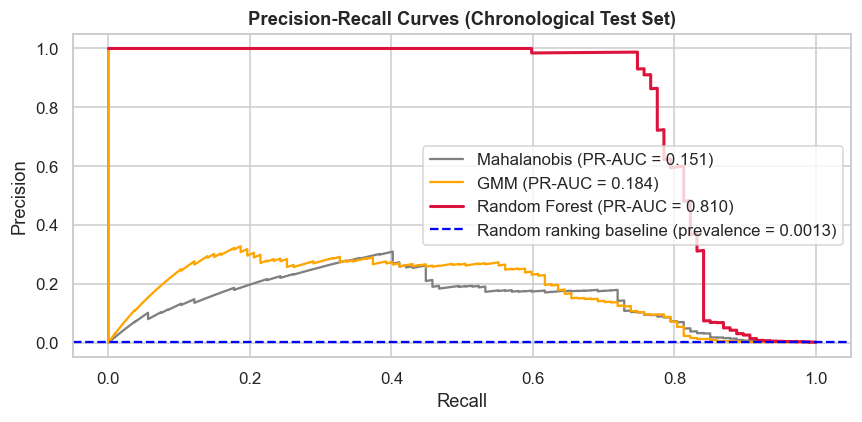

In [11]:
from sklearn.metrics import precision_recall_curve

# ============================================================
# Precision-Recall Curve Comparison
# ============================================================
# Plotting the full PR curve for all three models to visually compare their ranking quality across all thresholds, 
# not just at top-k.

# 1. Computing PR curves for all three methods
prec_maha, rec_maha, _ = precision_recall_curve(y_test, maha_dist)
prec_gmm, rec_gmm, _   = precision_recall_curve(y_test, gmm_anomaly_scores)
prec_rf, rec_rf, _     = precision_recall_curve(y_test, rf_scores)

# 2. Plotting the curves
plt.figure(figsize=(8, 4))

plt.plot(rec_maha, prec_maha, label=f"Mahalanobis (PR-AUC = {maha_results['PR_AUC']:.3f})", color="grey")
plt.plot(rec_gmm, prec_gmm, label=f"GMM (PR-AUC = {gmm_results['PR_AUC']:.3f})", color="orange")
plt.plot(rec_rf, prec_rf, label=f"Random Forest (PR-AUC = {rf_results['PR_AUC']:.3f})", color="crimson", linewidth=2)

# Adding a random ranking baseline
plt.axhline(y=y_test.mean(), color='blue', linestyle='--', label=f"Random ranking baseline (prevalence = {y_test.mean():.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves (Chronological Test Set)")
plt.legend(loc="center right")
plt.grid(True)
plt.tight_layout()
plt.show()

### Precision-Recall Curve Comparison

The precision-recall (PR) curve provides a picture of model performance across different classification thresholds, rather than being limited to specific ranking cut-offs.

The plot clearly illustrates the performance differences across the three models:

1. **Random Forest (Red):** The curve starts at a perfect precision of 1.0 and maintains high precision as recall increases. This indicates that the model successfully ranks many fraudulent transactions ahead of legitimate ones. However, precision gradually declines as the model includes more borderline transactions to identify additional fraud cases. The steeper decline at higher recall levels suggests that identifying the remaining fraud cases comes at the cost of an increasing number of false positives.

2. **GMM (Orange):** The cluster-based model achieves a considerably lower precision than Random Forest, with a maximum of roughly 0.35. This indicates that even at relatively low recall levels, the model includes more legitimate transactions among its highest-ranked anomalies. Its Average Precision of 0.1838 is nevertheless higher than that of the Mahalanobis baseline.

3. **Mahalanobis (Grey):** The statistical baseline performs worst among the three models. Its curve generally remains below the GMM curve, indicating weaker precision-recall performance across the range of thresholds. This is consistent with its lower Average Precision of 0.1506.

The dashed blue line at the bottom represents the random-ranking baseline, where expected precision corresponds approximately to the test-set fraud prevalence of 0.13%. All three models perform above this reference line, but Random Forest achieves substantially stronger precision-recall performance, with an Average Precision of 0.8095. This demonstrates its superior ability to rank fraudulent transactions ahead of legitimate ones on the test set.

## Why an Unusual Transaction is Not Necessarily Fraudulent

A central finding of this analysis is that anomaly detection and fraud detection are not the same thing. The Mahalanobis baseline and the Gaussian Mixture Model (GMM) were both designed to find *anomalies*, which are transactions that deviate from the learned statistical norm of the legitimate class. Yet the evaluation showed that their PR-AUC scores (0.1506 and 0.1838 respectively) were vastly inferior to the supervised Random Forest (0.8095).

This massive performance gap illustrates exactly why an unusual transaction is not necessarily fraudulent, for three key reasons:

1.  **Legitimate behaviour is highly diverse.** The PCA components (`V1`–`V28`) capture the variance of the legitimate class. A customer making a very large purchase, travelling to a new country, or shopping at an unusual hour will naturally produce an anomalous feature vector. The unsupervised models assign high anomaly scores to these transactions simply because they are rare, not because they are fraudulent. In reality, most statistical outliers in a transaction dataset are perfectly legitimate.
2.  **Fraud can look normal.** Conversely, fraudsters often deliberately mimic legitimate behaviour to avoid detection. A small fraudulent charge at a familiar merchant, made at a normal time of day, will look statistically very similar to a legitimate transaction. The Mahalanobis baseline and GMM missed many of these cases because the fraudulent transaction did not stand out as an outlier. Anomaly detectors are blind to fraud that hides within the normal distribution.
3.  **The supervised model learns the difference.** The Random Forest achieved vastly better performance because it learns from the labels. It is not just looking for weird transactions; it is learning the specific combinations of features that characterise *fraud* rather than mere rarity. A transaction that is unusual but not fraudulent will more likely receive a low fraud probability from the classifier because the model has learned to distinguish between legitimate rarity and fraudulent patterns.

**Practical Consequence for the Business**
An anomaly detector (such as the GMM) flags transactions for investigation, but it cannot tell an investigator whether a transaction is fraudulent. It simply ranks transactions by how unusual they are. If a bank deployed the GMM blindly, its investigators would waste significant time reviewing legitimate outliers while missing a large portion of actual frauds. 

The Random Forest, by contrast, prioritises transactions based on their probability of *being fraud*, which is exactly what the business needs. However, even the Random Forest is not infallible; at Precision@100 it generates roughly 17 false alarms. Therefore, the model serves as a prioritisation tool to support human investigators, not as an autonomous blocking system. An alert from the Random Forest should be combined with customer history and business rules before a transaction is declined or investigated.